In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

gap = px.data.gapminder()
gap_2007 = gap[gap["year"] == 2007]   # only the latest year

gap.head()


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4


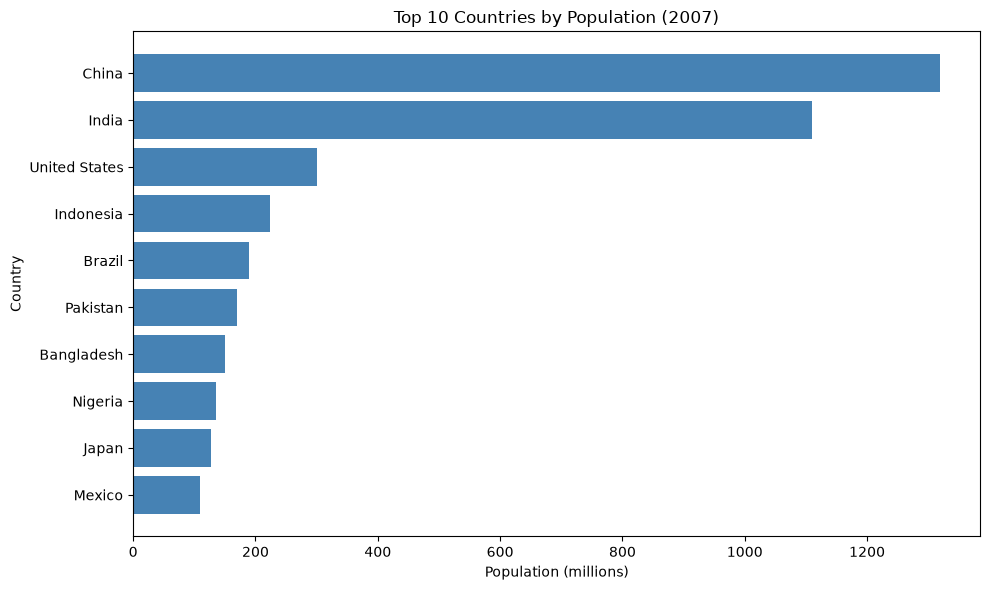

In [2]:
#Task 1
top10 = gap_2007.nlargest(10, "pop").copy()


top10["pop_millions"] = top10["pop"] / 1_000_000


top10 = top10.sort_values("pop_millions", ascending=True)


plt.figure(figsize=(10, 6))
plt.barh(top10["country"], top10["pop_millions"], color="steelblue")

plt.title("Top 10 Countries by Population (2007)")
plt.xlabel("Population (millions)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

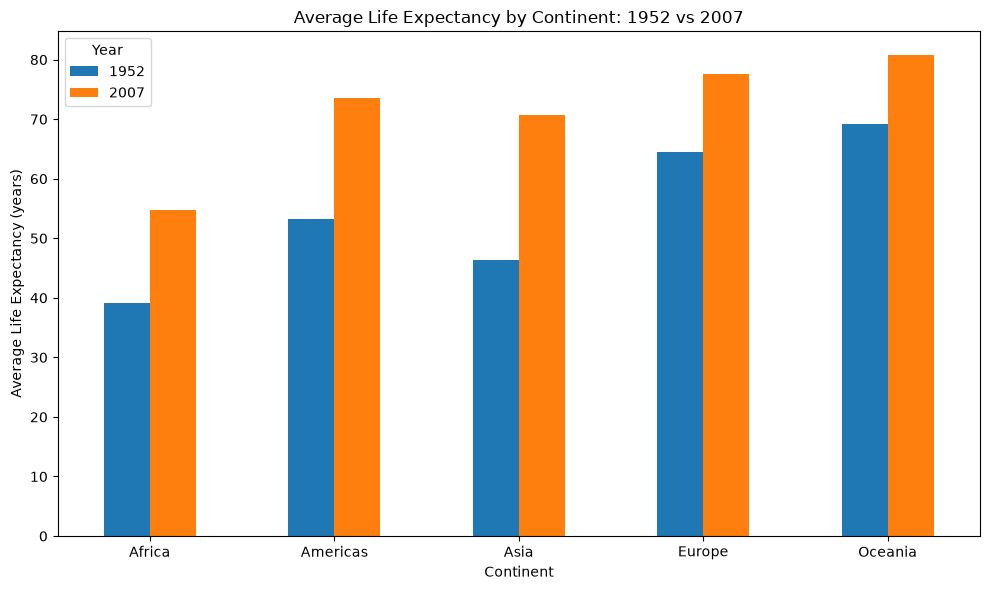

In [3]:
#Task 2

g = (
    gap[gap["year"].isin([1952, 2007])]
    .groupby(["continent", "year"])["lifeExp"]
    .mean()
    .unstack()
)

g.plot(kind="bar", figsize=(10, 6))

plt.title("Average Life Expectancy by Continent: 1952 vs 2007")
plt.xlabel("Continent")
plt.ylabel("Average Life Expectancy (years)")
plt.xticks(rotation=0)
plt.legend(title="Year")
plt.tight_layout()
plt.show()

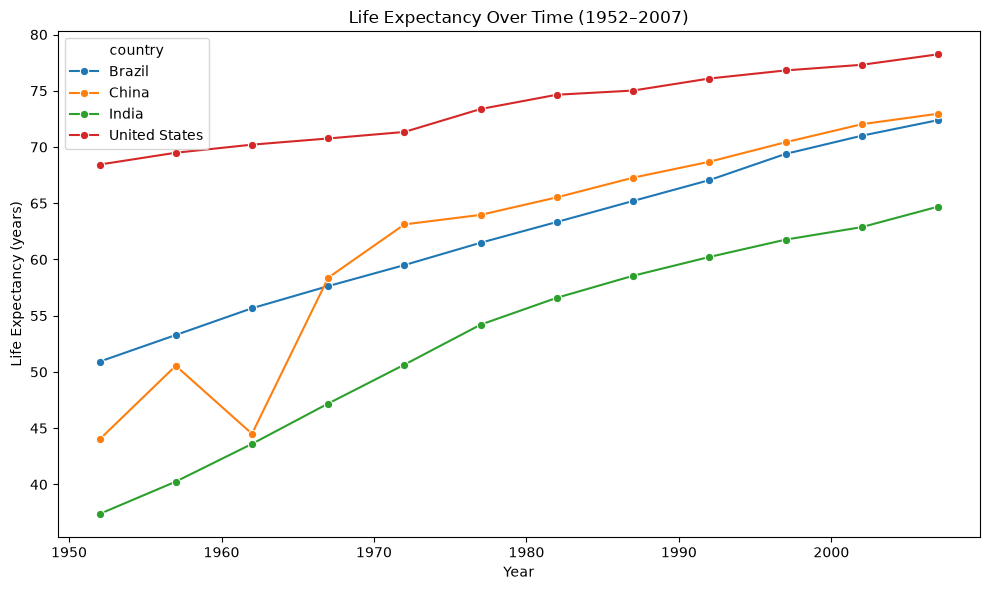

In [4]:
#Task 3
countries = ["India", "China", "Brazil", "United States"]

selected = gap[gap["country"].isin(countries)]


plt.figure(figsize=(10, 6))

sns.lineplot(
    data=selected,
    x="year",
    y="lifeExp",
    hue="country",
    marker="o"
)

plt.title("Life Expectancy Over Time (1952–2007)")
plt.xlabel("Year")
plt.ylabel("Life Expectancy (years)")
plt.tight_layout()
plt.show()

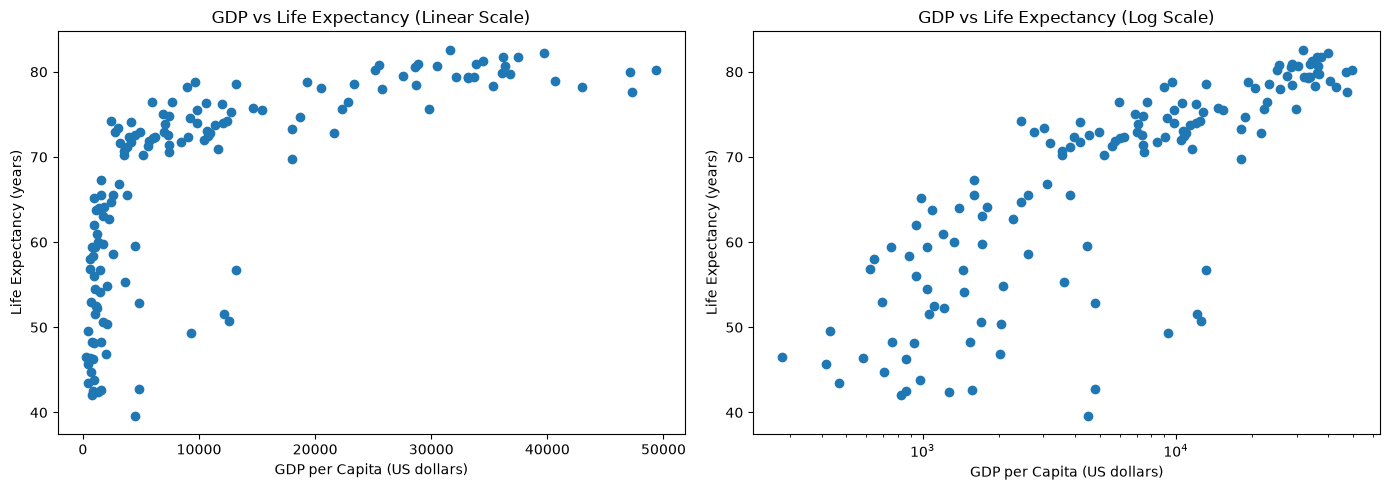

In [5]:
#Task 4
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(gap_2007["gdpPercap"], gap_2007["lifeExp"])
axes[0].set_title("GDP vs Life Expectancy (Linear Scale)")
axes[0].set_xlabel("GDP per Capita (US dollars)")
axes[0].set_ylabel("Life Expectancy (years)")

axes[1].scatter(gap_2007["gdpPercap"], gap_2007["lifeExp"])
axes[1].set_xscale("log")
axes[1].set_title("GDP vs Life Expectancy (Log Scale)")
axes[1].set_xlabel("GDP per Capita (US dollars)")
axes[1].set_ylabel("Life Expectancy (years)")

plt.tight_layout()
plt.show()

In [6]:
#Task 5
fig = px.scatter(
    gap_2007,
    x="gdpPercap",
    y="lifeExp",
    size="pop",
    color="continent",
    hover_name="country",
    log_x=True,
    size_max=50,
    title="GDP per Capita vs Life Expectancy by Continent (2007)",
    labels={
        "gdpPercap": "GDP per Capita (US dollars)",
        "lifeExp": "Life Expectancy (years)",
        "pop": "Population"
    }
)

fig.show()

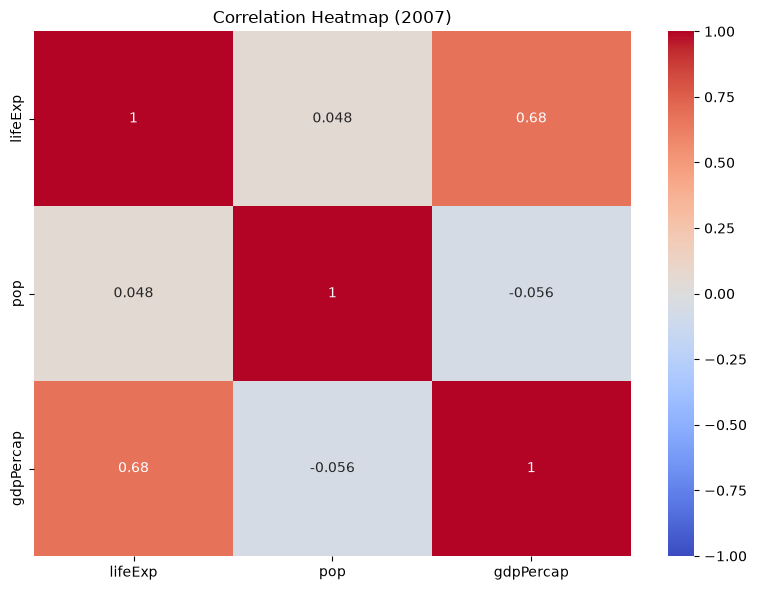

In [7]:
#Task 6

corr = gap_2007[["lifeExp", "pop", "gdpPercap"]].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap (2007)")
plt.tight_layout()
plt.show()

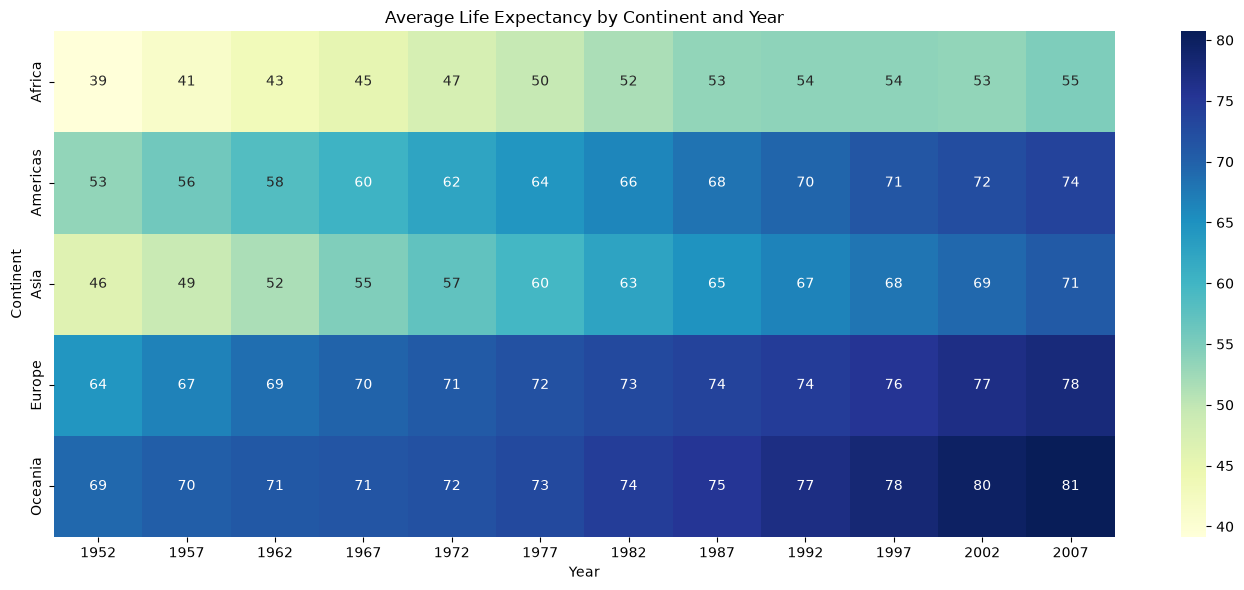

In [8]:
#Task 7

pivot = gap.pivot_table(
    index="continent",
    columns="year",
    values="lifeExp",
    aggfunc="mean"
)


plt.figure(figsize=(14, 6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Average Life Expectancy by Continent and Year")
plt.xlabel("Year")
plt.ylabel("Continent")
plt.tight_layout()
plt.show()

#Task 8
| Situation | Best chart | Reason |
|---|---|---|
| Compare the number of students in five branches | Bar chart | Compares values across different categories. |
| Show how a city's temperature changed month by month in a year | Line chart | Shows changes and trends over time. |
| Check whether more study hours go with higher marks | Scatter plot | Shows the relationship between two numerical variables. |
| Show how the marks of 100 students are spread out | Histogram | Shows the distribution of marks across intervals. |
| Show attendance of 5 subjects over 6 weeks in one view | Heatmap | Uses colour to show patterns across subjects and weeks. |

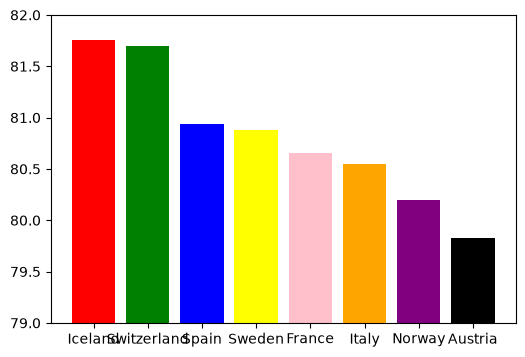

In [9]:
#Task 9
bad = gap_2007[gap_2007["continent"] == "Europe"].nlargest(8, "lifeExp")

plt.figure(figsize=(6, 4))

plt.bar(
    bad["country"],
    bad["lifeExp"],
    color=["red", "green", "blue", "yellow", "pink", "orange", "purple", "black"]
)

plt.ylim(79, 82)
plt.show()